# pcb_test

Coarse resonance sweep and lock-in spectrum from `D:\cw_odmr_lock_in\pcb_test`.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.style.use("plots.mplstyle")

run_name = "pcb_test2"
run_dir = Path(r"D:\cw_odmr_lock_in") / run_name

## Coarse resonance sweep (reflected power)

coarse dip: 2.8911 GHz, -50.0 dBm


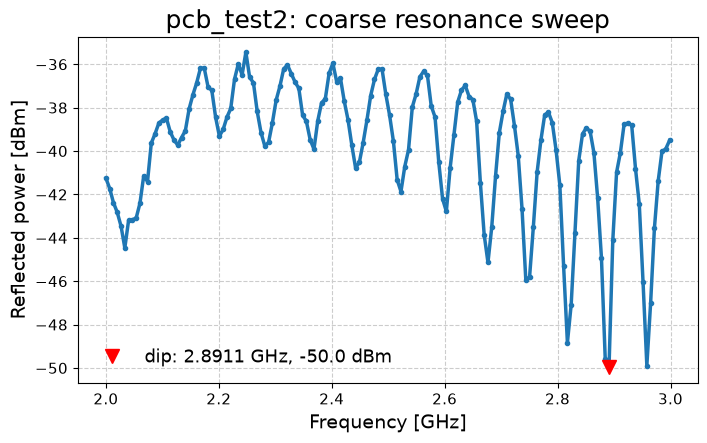

In [2]:
coarse = np.loadtxt(run_dir / f"{run_name}_resonance_coarse.csv", delimiter=",", skiprows=1)
freqs_hz, power_dbm = coarse[:, 0], coarse[:, 1]

i_dip = np.argmin(power_dbm)
f_dip_hz, p_dip_dbm = freqs_hz[i_dip], power_dbm[i_dip]
print(f"coarse dip: {f_dip_hz / 1e9:.4f} GHz, {p_dip_dbm:.1f} dBm")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(freqs_hz / 1e9, power_dbm, "o-")
ax.plot(f_dip_hz / 1e9, p_dip_dbm, "rv", markersize=10,
        label=f"dip: {f_dip_hz / 1e9:.4f} GHz, {p_dip_dbm:.1f} dBm")
ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Reflected power [dBm]")
ax.set_title(f"{run_name}: coarse resonance sweep")
ax.legend()
plt.show()

## Lock-in spectrum

Saturated points (stuck at the same value for 3+ consecutive points, i.e. sensitivity/ADC clipping) are grayed out.

In [3]:
def find_saturated_mask(values, min_run=3):
    """True where a point belongs to a run of >= min_run consecutive identical values."""
    values = np.asarray(values)
    mask = np.zeros(len(values), dtype=bool)
    run_start = 0
    for i in range(1, len(values) + 1):
        if i == len(values) or not np.isclose(values[i], values[i - 1], rtol=1e-9, atol=0):
            if i - run_start >= min_run:
                mask[run_start:i] = True
            run_start = i
    return mask


spec_prefix = f"{run_name}_lockin_spectrum"
spec_freqs_hz = np.load(run_dir / f"{spec_prefix}_freqs_hz.npy")
x_v = np.load(run_dir / f"{spec_prefix}_x.npy")
y_v = np.load(run_dir / f"{spec_prefix}_y.npy")
r_v = np.hypot(x_v, y_v)
reflected_dbm = np.load(run_dir / f"{spec_prefix}_reflected_dbm.npy")

print((run_dir / f"{spec_prefix}_metadata.txt").read_text())
sat = find_saturated_mask(x_v)
print(f"{len(spec_freqs_hz)} points, {spec_freqs_hz.min() / 1e9:.6f}-{spec_freqs_hz.max() / 1e9:.6f} GHz, "
      f"{sat.sum()} flagged saturated")

chop_freq_hz=1000.0
chop_duty_pct=50.0
time_constant_s=0.1
settle_time_constants=5.0
sensitivity_v=0.0001
phase_deg=0.0
drive_power_dbm=-15.0

101 points, 2.860000-2.880000 GHz, 0 flagged saturated


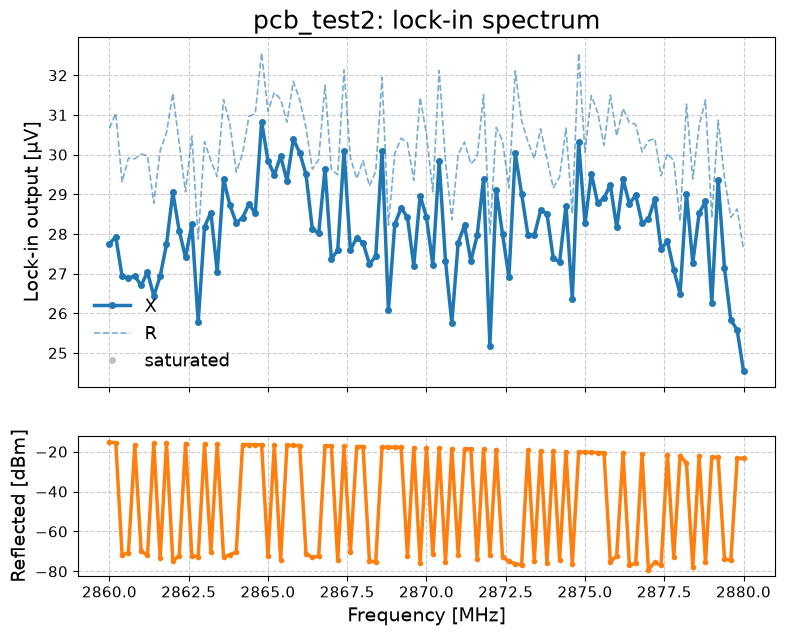

In [4]:
f_mhz = spec_freqs_hz / 1e6
x_uv, r_uv = x_v * 1e6, r_v * 1e6

fig, axs = plt.subplot_mosaic([["lockin"], ["refl"]], sharex=True, figsize=(9, 7),
                              height_ratios=[2.5, 1])
ax = axs["lockin"]
ax.plot(f_mhz, np.where(sat, np.nan, x_uv), "o-", ms=4, color="C0", label="X")
ax.plot(f_mhz, np.where(sat, np.nan, r_uv), "--", lw=1.2, alpha=0.6, color="C0", label="R")
ax.plot(f_mhz[sat], x_uv[sat], "o", ms=4, color="0.75", label="saturated")
ax.set_ylabel("Lock-in output [µV]")
ax.set_title(f"{run_name}: lock-in spectrum")
ax.legend()

axs["refl"].plot(f_mhz, reflected_dbm, "o-", ms=3, color="C1")
axs["refl"].set_ylabel("Reflected [dBm]")
axs["refl"].set_xlabel("Frequency [MHz]")
plt.show()

## pcb_test3: sweep-average repeats (coil 0 A, -10 dBm)

Averages every full-length repeat found on disk (partial repeats skipped), so rerun this as more repeats land. Gray lines are individual repeats.

In [5]:
import re


def sem(reps):
    """Standard error of the mean across repeats (axis 0); zeros if only one repeat."""
    n = len(reps)
    return reps.std(axis=0, ddof=1) / np.sqrt(n) if n > 1 else np.zeros(reps.shape[1])


def load_repeats(name, data_dir=Path(r"D:\cw_odmr_lock_in")):
    """Stack every full-length sweep-average repeat on disk (partial repeats skipped).

    The full grid is taken from the longest repeat, so a partial repeat 0 doesn't
    become the reference.

    Returns
    -------
    freqs_hz : 1D np.ndarray
    x_reps, y_reps, refl_reps : 2D np.ndarray, shape (n_repeats, len(freqs_hz))
        X/Y in V, reflected power in dBm.
    """
    run_dir = data_dir / name
    rep_pattern = re.compile(rf"{re.escape(name)}_repeat(\d+)_x\.npy")
    rep_ids = sorted(int(m.group(1)) for p in run_dir.glob("*_repeat*_x.npy")
                     if (m := rep_pattern.fullmatch(p.name)))

    grids = {r: np.load(run_dir / f"{name}_repeat{r}_freqs_hz.npy") for r in rep_ids}
    freqs_hz = max(grids.values(), key=len)
    x_list, y_list, refl_list, skipped = [], [], [], []
    for r in rep_ids:
        if len(grids[r]) != len(freqs_hz):
            skipped.append(r)
            continue
        stem = run_dir / f"{name}_repeat{r}"
        x_list.append(np.load(f"{stem}_x.npy"))
        y_list.append(np.load(f"{stem}_y.npy"))
        refl_list.append(np.load(f"{stem}_reflected_dbm.npy"))

    x_reps, y_reps, refl_reps = np.stack(x_list), np.stack(y_list), np.stack(refl_list)
    print(f"{name}: {len(x_reps)} full repeat(s) used, {len(freqs_hz)} points each, "
          f"{freqs_hz.min() / 1e9:.6f}-{freqs_hz.max() / 1e9:.6f} GHz"
          + (f"; skipped partial repeat(s) {skipped}" if skipped else ""))

    avg_x_path = run_dir / f"{name}_avg_x.npy"
    if avg_x_path.exists():
        print(f"saved _avg_x.npy matches this average: "
              f"{np.allclose(np.load(avg_x_path), x_reps.mean(axis=0))}")
    return freqs_hz, x_reps, y_reps, refl_reps


def plot_repeats(name):
    """Mean ± SEM of X and Y over repeats (individual repeats in gray), plus reflected power."""
    freqs_hz, x_reps, y_reps, refl_reps = load_repeats(name)
    f_mhz = freqs_hz / 1e6

    fig, axs = plt.subplot_mosaic([["x"], ["y"], ["refl"]], sharex=True, figsize=(9, 9),
                                  height_ratios=[2.5, 1.5, 1])
    if len(x_reps) > 1:
        for x_rep in x_reps:
            axs["x"].plot(f_mhz, x_rep * 1e6, "-", lw=0.8, alpha=0.3, color="0.5")
    label = f"mean of {len(x_reps)} ± SEM" if len(x_reps) > 1 else "single repeat"
    axs["x"].errorbar(f_mhz, x_reps.mean(axis=0) * 1e6, yerr=sem(x_reps) * 1e6, fmt="o",
                      ms=4, capsize=2, lw=1, color="C0", label=label)
    axs["x"].set_ylabel("X [µV]")
    axs["x"].set_title(f"{name}: averaged lock-in spectrum")
    axs["x"].legend()

    axs["y"].errorbar(f_mhz, y_reps.mean(axis=0) * 1e6, yerr=sem(y_reps) * 1e6, fmt="o",
                      ms=3, capsize=2, lw=1, color="C2")
    axs["y"].set_ylabel("Y [µV]")

    for i, refl in enumerate(refl_reps):
        axs["refl"].plot(f_mhz, refl, "o-", ms=2, lw=0.8, alpha=0.6, color=f"C{(i % 9) + 1}")
    axs["refl"].set_ylabel("Reflected [dBm]")
    axs["refl"].set_xlabel("Frequency [MHz]")
    plt.show()

pcb_test3: 5 full repeat(s) used, 101 points each, 2.860000-2.880000 GHz
saved _avg_x.npy matches this average: True


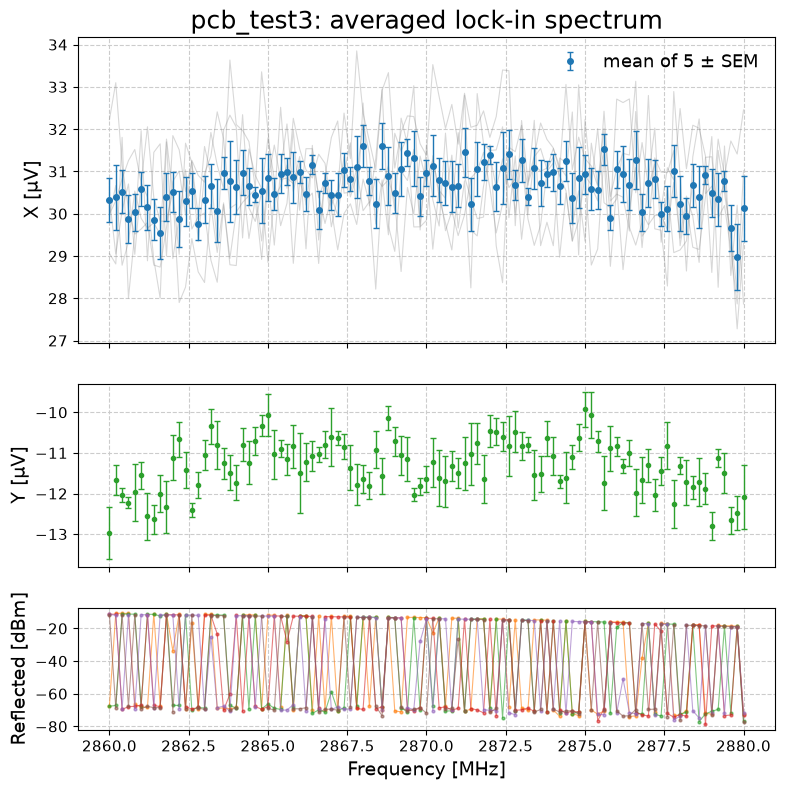

In [6]:
plot_repeats("pcb_test3")

## pcb_test5: sweep-average, 1 repeat (coil 0 A, -10 dBm, 2830-2900 MHz, 0.5 MHz step)

pcb_test5: 1 full repeat(s) used, 141 points each, 2.830000-2.900000 GHz
saved _avg_x.npy matches this average: True


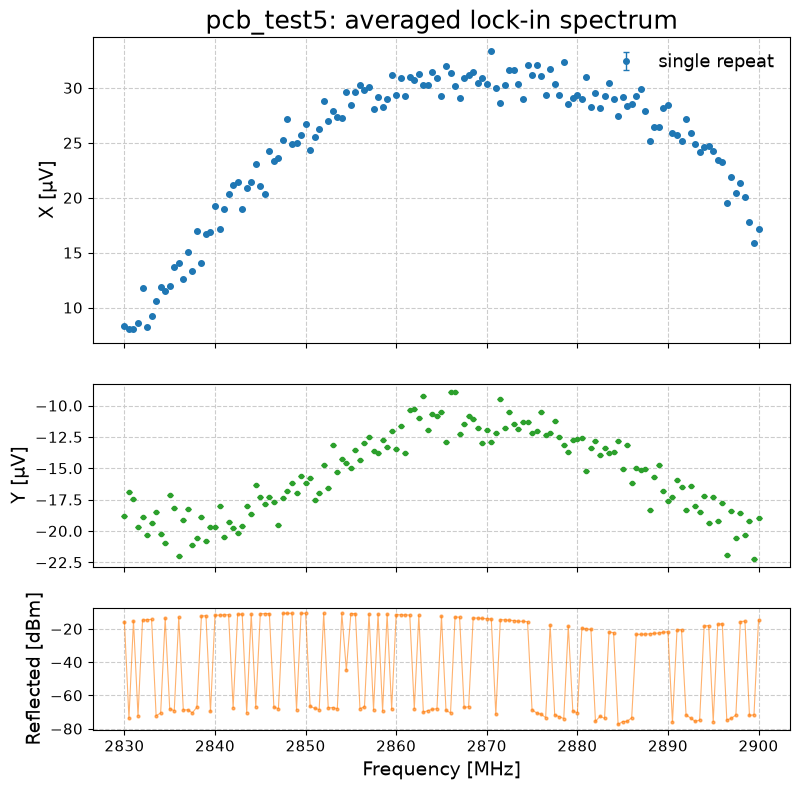

In [7]:
plot_repeats("pcb_test5")

## pcb_test6: sweep-average, 1 repeat (coil 1 A, -10 dBm, 2830-2900 MHz, 0.5 MHz step)

pcb_test6: 1 full repeat(s) used, 141 points each, 2.830000-2.900000 GHz
saved _avg_x.npy matches this average: True


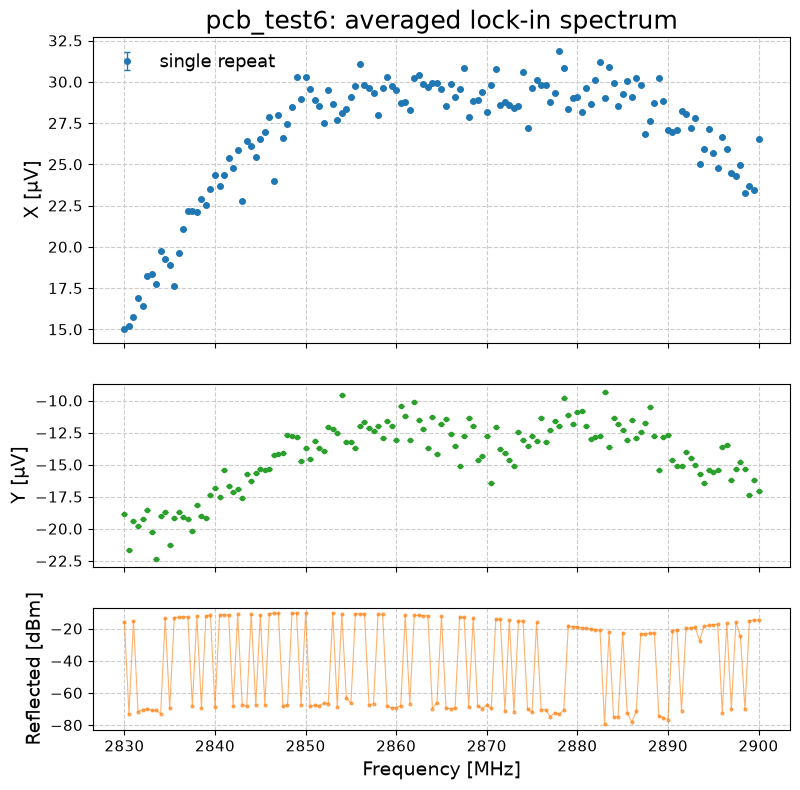

In [8]:
plot_repeats("pcb_test6")

## pcb_test6 vs pcb_test5: coil 1 A vs 0 A

Same scan settings, only the coil current differs. Anything that doesn't depend on the field (e.g. RF pickup) should cancel in the difference; ODMR should move.

pcb_test5: 1 full repeat(s) used, 141 points each, 2.830000-2.900000 GHz
saved _avg_x.npy matches this average: True
pcb_test6: 1 full repeat(s) used, 141 points each, 2.830000-2.900000 GHz
saved _avg_x.npy matches this average: True


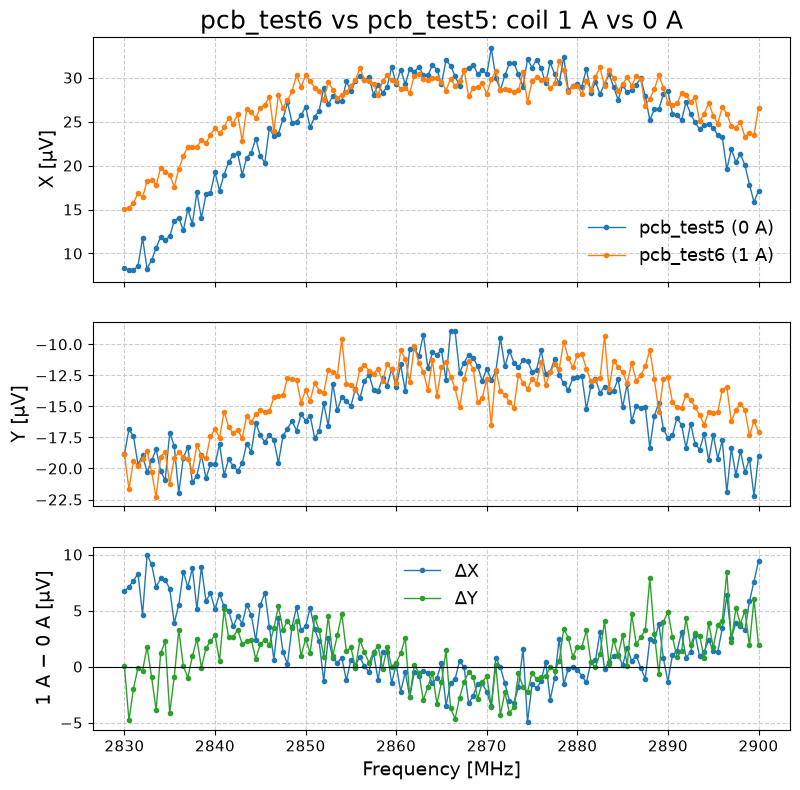

In [9]:
runs_cmp = {"pcb_test5 (0 A)": "pcb_test5", "pcb_test6 (1 A)": "pcb_test6"}
cmp = {label: load_repeats(name) for label, name in runs_cmp.items()}
(f5, x5, y5, _), (f6, x6, y6, _) = cmp.values()
assert np.allclose(f5, f6), "frequency grids differ"
f_mhz = f5 / 1e6

fig, axs = plt.subplot_mosaic([["x"], ["y"], ["diff"]], sharex=True, figsize=(9, 9),
                              height_ratios=[2, 1.5, 1.5])
for i, (label, (_, x_reps, y_reps, _)) in enumerate(cmp.items()):
    axs["x"].plot(f_mhz, x_reps.mean(axis=0) * 1e6, "o-", ms=3, lw=1, color=f"C{i}", label=label)
    axs["y"].plot(f_mhz, y_reps.mean(axis=0) * 1e6, "o-", ms=3, lw=1, color=f"C{i}")
axs["x"].set_ylabel("X [µV]")
axs["x"].set_title("pcb_test6 vs pcb_test5: coil 1 A vs 0 A")
axs["x"].legend()
axs["y"].set_ylabel("Y [µV]")

axs["diff"].plot(f_mhz, (x6.mean(axis=0) - x5.mean(axis=0)) * 1e6, "o-", ms=3, lw=1,
                 color="C0", label="ΔX")
axs["diff"].plot(f_mhz, (y6.mean(axis=0) - y5.mean(axis=0)) * 1e6, "o-", ms=3, lw=1,
                 color="C2", label="ΔY")
axs["diff"].axhline(0, color="k", lw=0.8)
axs["diff"].set_ylabel("1 A − 0 A [µV]")
axs["diff"].set_xlabel("Frequency [MHz]")
axs["diff"].legend()
plt.show()

## pcb_test7: sweep-average, 1 repeat (coil 1 A, -20 dBm, 2830-2900 MHz, 0.5 MHz step)

pcb_test7: 1 full repeat(s) used, 141 points each, 2.830000-2.900000 GHz
saved _avg_x.npy matches this average: True


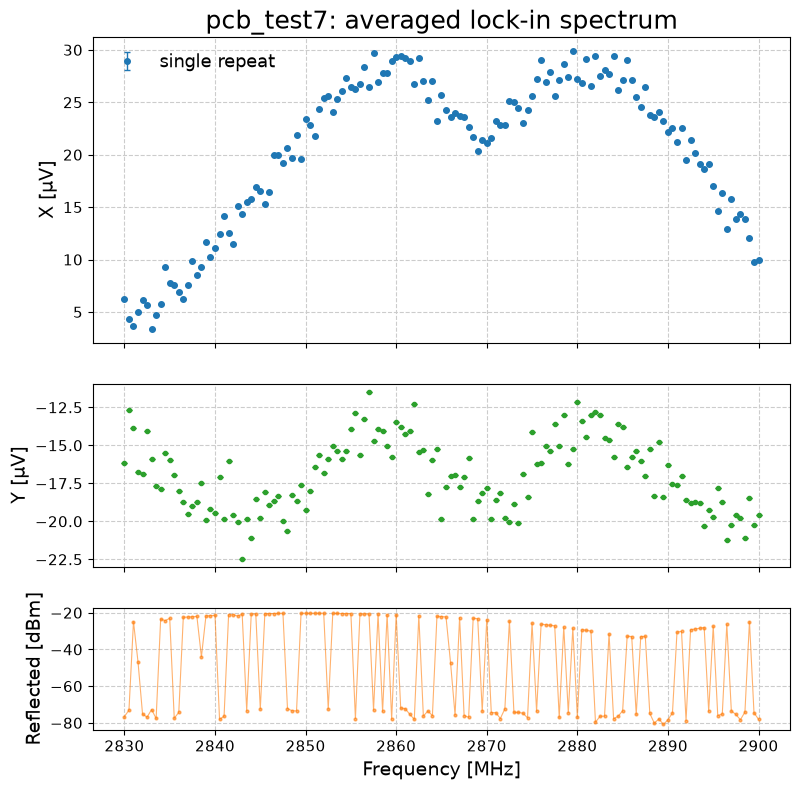

In [10]:
plot_repeats("pcb_test7")

## pcb_test7 vs pcb_test6: -20 vs -10 dBm (coil 1 A)

Same scan and coil current, only the drive power differs. If the width comes from power broadening, the -20 dBm feature should be narrower (compare the min-max scaled panel); pickup tracking the PCB's resonance should keep its shape.

pcb_test6: 1 full repeat(s) used, 141 points each, 2.830000-2.900000 GHz
saved _avg_x.npy matches this average: True
pcb_test7: 1 full repeat(s) used, 141 points each, 2.830000-2.900000 GHz
saved _avg_x.npy matches this average: True


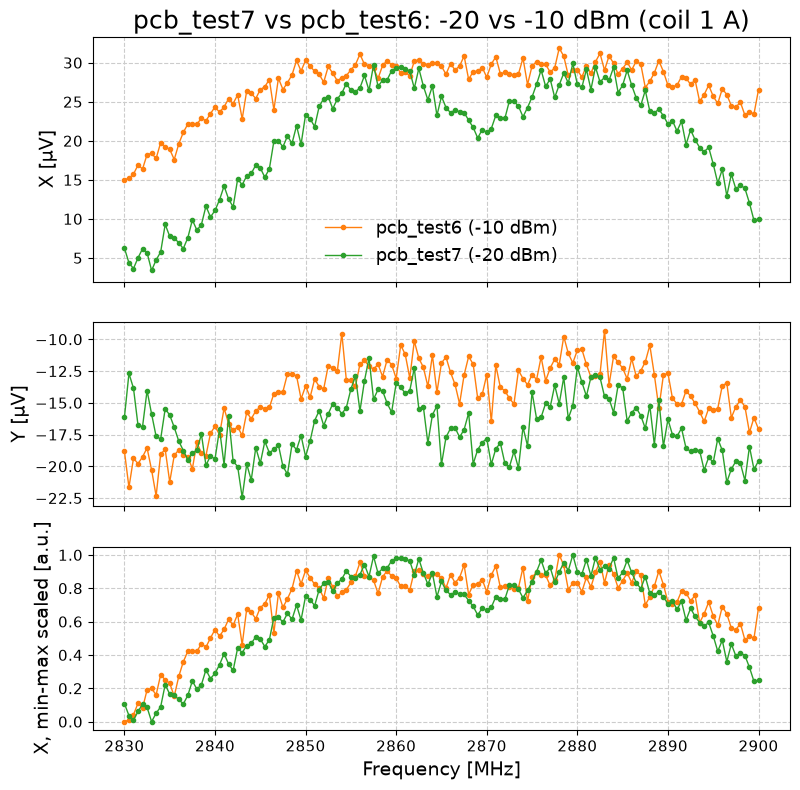

In [11]:
runs_pwr = {"pcb_test6 (-10 dBm)": "pcb_test6", "pcb_test7 (-20 dBm)": "pcb_test7"}
pwr = {label: load_repeats(name) for label, name in runs_pwr.items()}

fig, axs = plt.subplot_mosaic([["x"], ["y"], ["norm"]], sharex=True, figsize=(9, 9),
                              height_ratios=[2, 1.5, 1.5])
for i, (label, (freqs_hz, x_reps, y_reps, _)) in enumerate(pwr.items()):
    f_mhz = freqs_hz / 1e6
    x_uv, y_uv = x_reps.mean(axis=0) * 1e6, y_reps.mean(axis=0) * 1e6
    axs["x"].plot(f_mhz, x_uv, "o-", ms=3, lw=1, color=f"C{i + 1}", label=label)
    axs["y"].plot(f_mhz, y_uv, "o-", ms=3, lw=1, color=f"C{i + 1}")
    axs["norm"].plot(f_mhz, (x_uv - x_uv.min()) / (x_uv.max() - x_uv.min()), "o-", ms=3, lw=1,
                     color=f"C{i + 1}")
axs["x"].set_ylabel("X [µV]")
axs["x"].set_title("pcb_test7 vs pcb_test6: -20 vs -10 dBm (coil 1 A)")
axs["x"].legend()
axs["y"].set_ylabel("Y [µV]")
axs["norm"].set_ylabel("X, min-max scaled [a.u.]")
axs["norm"].set_xlabel("Frequency [MHz]")
plt.show()

## pcb_rabi_focus6: zero-field CW ODMR at the pcb_rabi6 focus (coil 0 A, -20 dBm, 2830-2920 MHz)

Taken to find the line centre(s) for the detuned Rabi runs. Repeat 0 stopped early on overloads (64/181 points) and is excluded; the average is repeat 1 only. The fit cell projects X/Y onto the main signal direction and compares one and two Lorentzian lines on a sloped background; dotted lines mark the Rabi drive frequencies.

pcb_rabi_focus6: 1 full repeat(s) used, 181 points each, 2.830000-2.920000 GHz; skipped partial repeat(s) [0]
saved _avg_x.npy matches this average: True


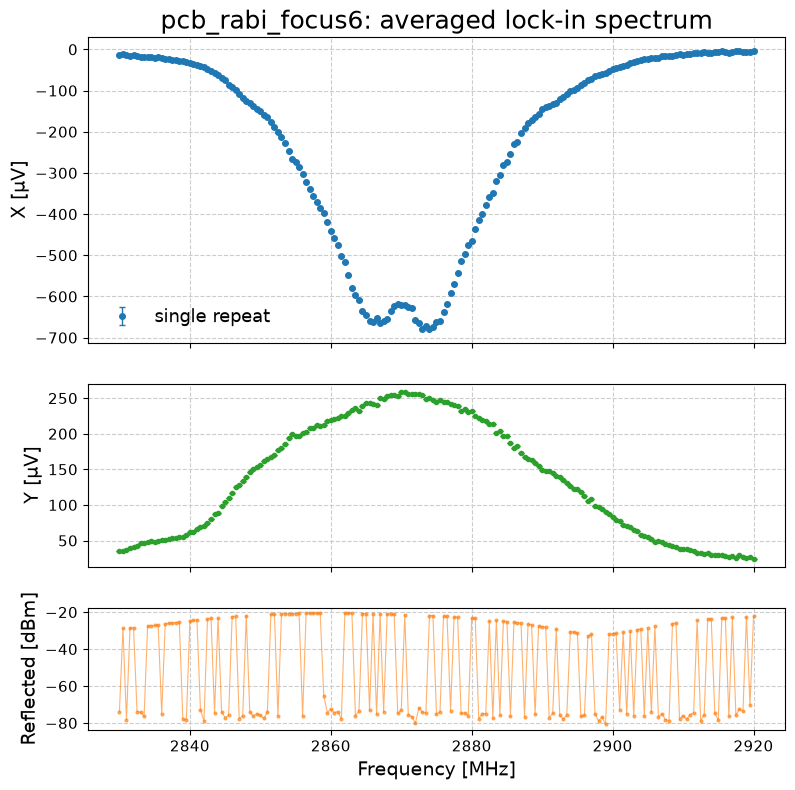

In [12]:
plot_repeats("pcb_rabi_focus6")

pcb_rabi_focus6: 1 full repeat(s) used, 181 points each, 2.830000-2.920000 GHz; skipped partial repeat(s) [0]
saved _avg_x.npy matches this average: True
signal direction 161.8 deg from X
candidate peaks (3-point smoothed): 2867.5, 2873.5 MHz
one line: centre 2870.1 +/- 0.1 MHz, FWHM 29.8 MHz, RSS/dof 485.4
two lines: 2864.5 +/- 0.3 MHz (FWHM 21.1) and 2875.7 +/- 0.3 MHz (FWHM 19.1); separation 11.2 MHz, midpoint 2870.1 MHz; RSS/dof 142.7


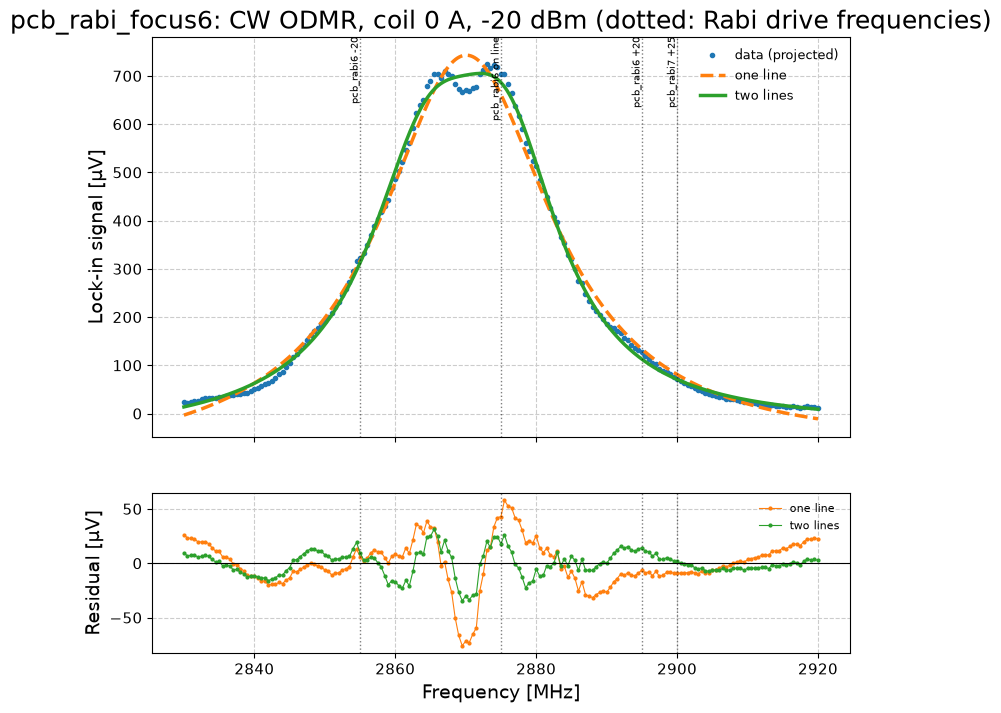

In [13]:
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

RABI_DRIVES_MHZ = {2855: "pcb_rabi6 -20", 2875: "pcb_rabi6 on line", 2895: "pcb_rabi6 +20",
                   2900: "pcb_rabi7 +25"}

f0_hz, x0_reps, y0_reps, _ = load_repeats("pcb_rabi_focus6")
f0_mhz = f0_hz / 1e6
x0, y0 = x0_reps.mean(axis=0), y0_reps.mean(axis=0)
xy = np.column_stack([x0 - x0.mean(), y0 - y0.mean()])
axis0 = np.linalg.svd(xy, full_matrices=False)[2][0]
s0 = (x0 * axis0[0] + y0 * axis0[1]) * 1e6
if np.abs(s0.max() - np.median(s0)) < np.abs(s0.min() - np.median(s0)):
    s0 = -s0
print(f"signal direction {np.degrees(np.arctan2(axis0[1], axis0[0])):.1f} deg from X")


def lorentz(f, center, fwhm):
    return (fwhm / 2) ** 2 / ((f - center) ** 2 + (fwhm / 2) ** 2)


def one_line(f, offset, slope, a, c, w):
    return offset + slope * (f - 2875) + a * lorentz(f, c, w)


def two_lines(f, offset, slope, a1, c1, w1, a2, c2, w2):
    return offset + slope * (f - 2875) + a1 * lorentz(f, c1, w1) + a2 * lorentz(f, c2, w2)


smooth = np.convolve(s0, np.ones(3) / 3, mode="same")
peaks, props = find_peaks(smooth[2:-2], prominence=0.01 * (smooth.max() - smooth.min()))
peaks += 2
top = np.sort(peaks[np.argsort(props["prominences"])[::-1][:2]])
print(f"candidate peaks (3-point smoothed): {', '.join(f'{f0_mhz[i]:.1f}' for i in top)} MHz")

base = np.median(np.r_[s0[:10], s0[-10:]])
p1, c1 = curve_fit(one_line, f0_mhz, s0, p0=[base, 0, s0.max() - base, f0_mhz[np.argmax(smooth)], 30],
                   maxfev=50000)
fits0 = {"one line": (one_line, p1, np.sqrt(np.diag(c1)), 5)}
ca, cb = (f0_mhz[top[0]], f0_mhz[top[1]]) if len(top) == 2 else (p1[3] - 4, p1[3] + 4)
p2, c2 = curve_fit(two_lines, f0_mhz, s0,
                   p0=[base, 0, (s0.max() - base) / 1.5, ca, 15, (s0.max() - base) / 1.5, cb, 15],
                   maxfev=50000)
fits0["two lines"] = (two_lines, p2, np.sqrt(np.diag(c2)), 8)

for label, (model, p, err, n_par) in fits0.items():
    rss = np.sum((s0 - model(f0_mhz, *p)) ** 2) / (len(s0) - n_par)
    if label == "one line":
        print(f"one line: centre {p[3]:.1f} +/- {err[3]:.1f} MHz, FWHM {abs(p[4]):.1f} MHz, RSS/dof {rss:.1f}")
    else:
        print(f"two lines: {p[3]:.1f} +/- {err[3]:.1f} MHz (FWHM {abs(p[4]):.1f}) and "
              f"{p[6]:.1f} +/- {err[6]:.1f} MHz (FWHM {abs(p[7]):.1f}); separation {abs(p[6] - p[3]):.1f} MHz, "
              f"midpoint {(p[3] + p[6]) / 2:.1f} MHz; RSS/dof {rss:.1f}")

fig, axs = plt.subplot_mosaic([["s"], ["resid"]], sharex=True, figsize=(9, 8), height_ratios=[2.5, 1])
axs["s"].plot(f0_mhz, s0, "o", ms=3, color="C0", label="data (projected)")
f_fine = np.linspace(f0_mhz.min(), f0_mhz.max(), 1000)
for i, (label, (model, p, _, _)) in enumerate(fits0.items()):
    axs["s"].plot(f_fine, model(f_fine, *p), "-" if label == "two lines" else "--", color=f"C{i + 1}",
                  label=label)
    axs["resid"].plot(f0_mhz, s0 - model(f0_mhz, *p), "o-", ms=2, lw=0.8, color=f"C{i + 1}", label=label)
for f_drive, label in RABI_DRIVES_MHZ.items():
    for key in ("s", "resid"):
        axs[key].axvline(f_drive, ls=":", lw=1, color="k", alpha=0.5)
    axs["s"].annotate(label, (f_drive, axs["s"].get_ylim()[1]), rotation=90, va="top", ha="right", fontsize=7)
axs["s"].set_ylabel("Lock-in signal [µV]")
axs["s"].set_title("pcb_rabi_focus6: CW ODMR, coil 0 A, -20 dBm (dotted: Rabi drive frequencies)")
axs["s"].legend(fontsize=9)
axs["resid"].axhline(0, color="k", lw=0.8)
axs["resid"].set_ylabel("Residual [µV]")
axs["resid"].set_xlabel("Frequency [MHz]")
axs["resid"].legend(fontsize=8)
plt.show()

## pcb_rabi_focus6_more_redo: CW ODMR at 3 A (-30 dBm, 2860-2950 MHz), same focus

One full repeat. The window covers the upper transition and only the tail of the lower one. The fit uses three Lorentzians on a sloped background: the lower line (centre below the window, constrained to < 2860 MHz) and the two peaks of the upper transition. The 0 A scan (pcb_rabi_focus6, -20 dBm) is overlaid, scaled to the same peak height.

pcb_rabi_focus6_more_redo: 1 full repeat(s) used, 181 points each, 2.860000-2.950000 GHz
saved _avg_x.npy matches this average: True


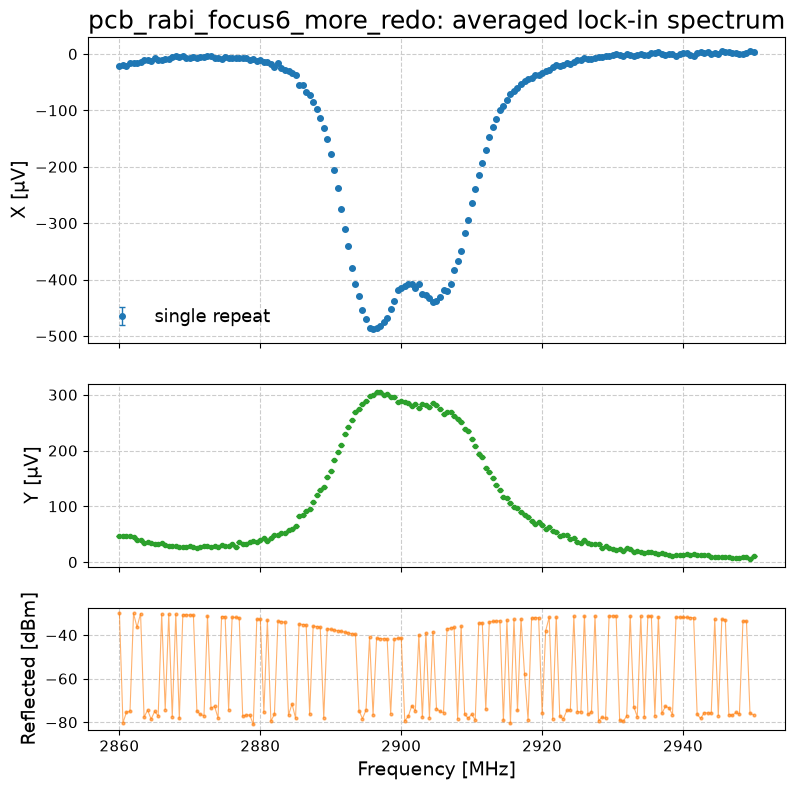

In [14]:
plot_repeats("pcb_rabi_focus6_more_redo")

pcb_rabi_focus6_more_redo: 1 full repeat(s) used, 181 points each, 2.860000-2.950000 GHz
saved _avg_x.npy matches this average: True
signal direction 148.6 deg from X
upper transition: peaks at 2895.6 +/- 0.0 MHz (FWHM 10.4) and 2905.7 +/- 0.1 MHz (FWHM 12.9); separation 10.1 MHz, midpoint 2900.7 MHz
lower transition (centre outside the window, only its tail is fitted): 2858.3 +/- 1.8 MHz, FWHM 35.4 MHz
RSS/dof 49.8
upper midpoint is +30.6 MHz from the zero-field centre -> gamma*B_par ≈ 30.1 MHz, B ≈ 18.6 G at 3 A (≈ 6.2 G/A, field along [100])


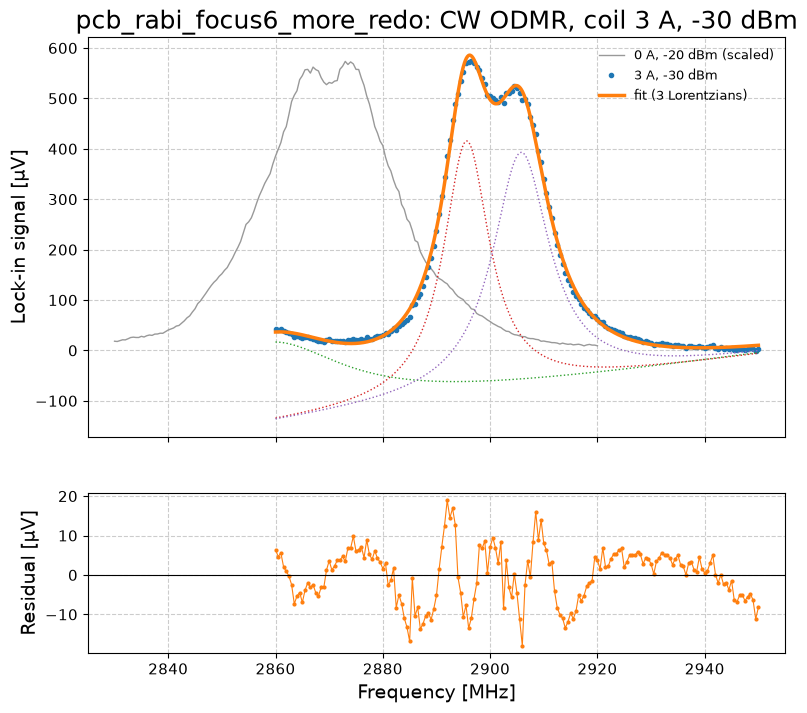

In [15]:
def three_lines(f, offset, slope, a0, c0, w0, a1, c1, w1, a2, c2, w2):
    return (offset + slope * (f - 2875) + a0 * lorentz(f, c0, w0)
            + a1 * lorentz(f, c1, w1) + a2 * lorentz(f, c2, w2))


f3_hz, x3_reps, y3_reps, _ = load_repeats("pcb_rabi_focus6_more_redo")
f3_mhz = f3_hz / 1e6
x3, y3 = x3_reps.mean(axis=0), y3_reps.mean(axis=0)
xy3 = np.column_stack([x3 - x3.mean(), y3 - y3.mean()])
axis3 = np.linalg.svd(xy3, full_matrices=False)[2][0]
s3 = (x3 * axis3[0] + y3 * axis3[1]) * 1e6
if np.abs(s3.max() - np.median(s3)) < np.abs(s3.min() - np.median(s3)):
    s3 = -s3
print(f"signal direction {np.degrees(np.arctan2(axis3[1], axis3[0])):.1f} deg from X")

# Upper transition split into two peaks, plus the tail of the lower transition just below the window.
p0_3 = [0, 0, 300, 2843, 20, 450, 2896.5, 10, 400, 2904.5, 10]
lo = [-np.inf, -np.inf, 0, 2800, 2, 0, 2885, 2, 0, 2895, 2]
hi = [np.inf, np.inf, np.inf, 2860, 60, np.inf, 2902, 40, np.inf, 2915, 40]
p3, c3 = curve_fit(three_lines, f3_mhz, s3, p0=p0_3, bounds=(lo, hi), maxfev=100000)
e3 = np.sqrt(np.diag(c3))
rss3 = np.sum((s3 - three_lines(f3_mhz, *p3)) ** 2) / (len(s3) - len(p3))
upper_mid = (p3[6] + p3[9]) / 2
print(f"upper transition: peaks at {p3[6]:.1f} +/- {e3[6]:.1f} MHz (FWHM {p3[7]:.1f}) and "
      f"{p3[9]:.1f} +/- {e3[9]:.1f} MHz (FWHM {p3[10]:.1f}); separation {p3[9] - p3[6]:.1f} MHz, "
      f"midpoint {upper_mid:.1f} MHz")
print(f"lower transition (centre outside the window, only its tail is fitted): {p3[3]:.1f} +/- {e3[3]:.1f} MHz, "
      f"FWHM {p3[4]:.1f} MHz")
print(f"RSS/dof {rss3:.1f}")

# Field estimate from the upper transition's shift, using the zero-field fit: centre 2870.1 MHz, 2E = 11.2 MHz.
zf_centre, e_mhz = 2870.1, 11.2 / 2
gamma_par = np.sqrt(max((upper_mid - zf_centre) ** 2 - e_mhz ** 2, 0))
print(f"upper midpoint is {upper_mid - zf_centre:+.1f} MHz from the zero-field centre -> "
      f"gamma*B_par ≈ {gamma_par:.1f} MHz, B ≈ {gamma_par / 1.62:.1f} G at 3 A "
      f"(≈ {gamma_par / 1.62 / 3:.1f} G/A, field along [100])")

fig, axs = plt.subplot_mosaic([["s"], ["resid"]], sharex=True, figsize=(9, 8), height_ratios=[2.5, 1])
axs["s"].plot(f0_mhz, s0 * s3.max() / s0.max(), "-", lw=1, color="0.6", label="0 A, -20 dBm (scaled)")
axs["s"].plot(f3_mhz, s3, "o", ms=3, color="C0", label="3 A, -30 dBm")
f_fine3 = np.linspace(f3_mhz.min(), f3_mhz.max(), 1000)
axs["s"].plot(f_fine3, three_lines(f_fine3, *p3), "-", color="C1", label="fit (3 Lorentzians)")
for k, c in ((3, "C2"), (6, "C3"), (9, "C4")):
    axs["s"].plot(f_fine3, p3[0] + p3[1] * (f_fine3 - 2875) + p3[k - 1] * lorentz(f_fine3, p3[k], p3[k + 1]),
                  ":", color=c, lw=1)
axs["s"].set_ylabel("Lock-in signal [µV]")
axs["s"].set_title("pcb_rabi_focus6_more_redo: CW ODMR, coil 3 A, -30 dBm")
axs["s"].legend(fontsize=9)
axs["resid"].plot(f3_mhz, s3 - three_lines(f3_mhz, *p3), "o-", ms=2, lw=0.8, color="C1")
axs["resid"].axhline(0, color="k", lw=0.8)
axs["resid"].set_ylabel("Residual [µV]")
axs["resid"].set_xlabel("Frequency [MHz]")
axs["s"].set_xlim(2825, 2955)
plt.show()

## pcb_rabi_focus6_more: pre-sweep resonance check (3 A, -30 dBm)

`sweep-average`'s `check_resonance_before_sweep` reads reflected power across the scan range at the drive power before the repeats start. The ODMR scan from `_redo` (same window and settings) is shown underneath, with its two fitted peaks dotted.

resonance check: 181 points, 2860.0-2950.0 MHz; lowest reading -79.3 dBm at 2920.5 MHz; readings span -79.3 to -29.9 dBm


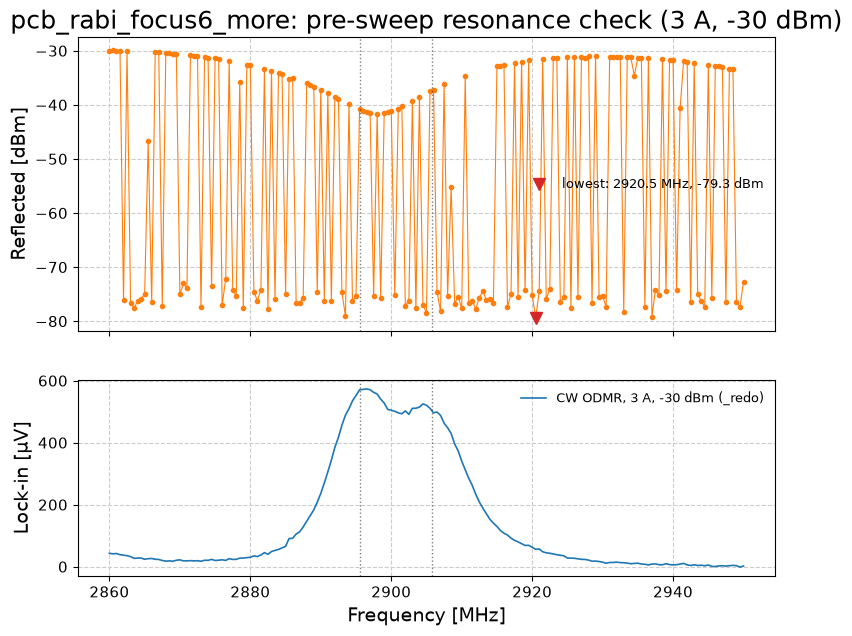

In [16]:
rc_dir = Path(r"D:\cw_odmr_lock_in") / "pcb_rabi_focus6_more"
rc_f_mhz = np.load(rc_dir / "pcb_rabi_focus6_more_resonance_check_freqs_hz.npy") / 1e6
rc_dbm = np.load(rc_dir / "pcb_rabi_focus6_more_resonance_check_reflected_dbm.npy")
i_min = np.nanargmin(rc_dbm)
print(f"resonance check: {len(rc_f_mhz)} points, {rc_f_mhz.min():.1f}-{rc_f_mhz.max():.1f} MHz; "
      f"lowest reading {rc_dbm[i_min]:.1f} dBm at {rc_f_mhz[i_min]:.1f} MHz; "
      f"readings span {np.nanmin(rc_dbm):.1f} to {np.nanmax(rc_dbm):.1f} dBm")

fig, axs = plt.subplot_mosaic([["refl"], ["odmr"]], sharex=True, figsize=(9, 7), height_ratios=[1.5, 1])
axs["refl"].plot(rc_f_mhz, rc_dbm, "o-", ms=3, lw=0.8, color="C1")
axs["refl"].plot(rc_f_mhz[i_min], rc_dbm[i_min], "v", ms=9, color="C3",
                 label=f"lowest: {rc_f_mhz[i_min]:.1f} MHz, {rc_dbm[i_min]:.1f} dBm")
axs["refl"].set_ylabel("Reflected [dBm]")
axs["refl"].set_title("pcb_rabi_focus6_more: pre-sweep resonance check (3 A, -30 dBm)")
axs["refl"].legend(fontsize=9)
axs["odmr"].plot(f3_mhz, s3, "-", lw=1.2, color="C0", label="CW ODMR, 3 A, -30 dBm (_redo)")
for c in (p3[6], p3[9]):
    for key in ("refl", "odmr"):
        axs[key].axvline(c, ls=":", lw=1, color="k", alpha=0.5)
axs["odmr"].set_ylabel("Lock-in [µV]")
axs["odmr"].set_xlabel("Frequency [MHz]")
axs["odmr"].legend(fontsize=9)
plt.show()